In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
data_df = pd.read_csv("/content/gridflow_2025_unified_data.csv")

In [3]:
data_df['MODEL_TIME'] = pd.to_datetime(data_df['MODEL_TIME'])

In [4]:
data_df["SETTLEMENT_DATE"] = pd.to_datetime(data_df["SETTLEMENT_DATE"])

In [5]:
data_df["DISPATCH_DEMAND"] = (data_df["UNDERLYING_DEMAND"]
                              - data_df["HYDRO"]
                              -data_df["COAL"]
                              -data_df["IMPORTS"]
                              -data_df["OTHER"]
                              )

In [6]:
baseline_df = pd.read_csv("/content/gridflow_2025_baseline_results__data.csv")

In [7]:
baseline_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   MODEL_TIME               17520 non-null  object 
 1   DISPATCH_DEMAND          17520 non-null  float64
 2   Hourly Operating Cost    17520 non-null  float64
 3   Operating Cost (30mins)  17520 non-null  float64
 4   Optimal Wind             17520 non-null  float64
 5   Optimal Solar            17520 non-null  float64
 6   Optimal Nuclear          17520 non-null  float64
 7   Optimal Biomass          17520 non-null  float64
 8   Optimal Gas              17520 non-null  float64
 9   Marginal Price           17520 non-null  float64
dtypes: float64(9), object(1)
memory usage: 1.3+ MB


In [8]:
baseline_df['MODEL_TIME'] = pd.to_datetime(baseline_df['MODEL_TIME'])

In [9]:
baseline_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype              
---  ------                   --------------  -----              
 0   MODEL_TIME               17520 non-null  datetime64[ns, UTC]
 1   DISPATCH_DEMAND          17520 non-null  float64            
 2   Hourly Operating Cost    17520 non-null  float64            
 3   Operating Cost (30mins)  17520 non-null  float64            
 4   Optimal Wind             17520 non-null  float64            
 5   Optimal Solar            17520 non-null  float64            
 6   Optimal Nuclear          17520 non-null  float64            
 7   Optimal Biomass          17520 non-null  float64            
 8   Optimal Gas              17520 non-null  float64            
 9   Marginal Price           17520 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(9)
memory usage: 1.3 MB


In [10]:
battery_parameters = {
    "power_capacity":2000, #MW
    "energy_capacity": 4000, #MWh
    "charging_effeciency":0.95,
    "discharging_effeciency":0.95,
    "initial_SOC": 2000, #MWh
    "final_SOC":2000 #MWh
}

dt = 0.5

In [11]:
T = len(data_df)

wind_id = np.arange(0,T)
solar_id = np.arange(T,2*T)
nuclear_id = np.arange(2*T,3*T)
biomass_id = np.arange(3*T,4*T)
gas_id = np.arange(4*T,5*T)
charge_id = np.arange(5*T,6*T)
discharge_id = np.arange(6*T,7*T)
soc_id = np.arange(7*T,8*T)

In [12]:
print(T)
print("Total variables: ",8*T)
print(wind_id[:3],wind_id[-3:])
print(soc_id[:3],soc_id[-3:])


17520
Total variables:  140160
[0 1 2] [17517 17518 17519]
[122640 122641 122642] [140157 140158 140159]


In [13]:
#marginal costs (£/MWh)

#capacities (MW)
#wind and solar limits are time varying instead of being a fixed annual maximum


technology_parameters = {
    "WIND":{
        "treatment": "optimised",
        "marginal_cost":4.00,
        "capacity":"time_varying"},

    "SOLAR":{
        "treatment": "optimised",
        "marginal_cost":0.00,
        "capacity":"time_varying"},

    "NUCLEAR":{
        "treatment": "optimised",
        "marginal_cost":17,
        "capacity":5302},

    "BIOMASS":{
        "treatment": "optimised",
        "marginal_cost":85.00,
        "capacity":3394},

    "GAS":{
        "treatment": "optimised",
        "marginal_cost":80.00,
        "capacity":27250},

    "HYDRO":{
        "treatment": "fixed_observed"},

    "COAL":{
        "treatment": "fixed_observed"},


    "OTHER":{
        "treatment": "fixed_observed"},

    "IMPORTS":{
        "treatment": "fixed_observed"}
}






In [14]:
cost = np.zeros(8*T)

cost[wind_id] = technology_parameters["WIND"]["marginal_cost"]
cost[solar_id] = technology_parameters["SOLAR"]["marginal_cost"]
cost[nuclear_id] = technology_parameters["NUCLEAR"]["marginal_cost"]
cost[biomass_id] = technology_parameters["BIOMASS"]["marginal_cost"]
cost[gas_id] = technology_parameters["GAS"]["marginal_cost"]



In [15]:
print(cost.shape)
print(np.unique(cost,return_counts = True))

(140160,)
(array([ 0.,  4., 17., 80., 85.]), array([70080, 17520, 17520, 17520, 17520]))


In [16]:
bounds =(
    [(0,data_df["TOTAL_WIND"].iloc[t]) for t in range(T)]+
     [(0,data_df["SOLAR"].iloc[t]) for t in range(T)]+
     [(0,technology_parameters["NUCLEAR"]["capacity"])]*T+
     [(0,technology_parameters["BIOMASS"]["capacity"])]*T+
     [(0,technology_parameters["GAS"]["capacity"])]*T+
    [(0,battery_parameters["power_capacity"])]*T+ #charging
    [(0,battery_parameters["power_capacity"])]*T+ #discharging
    [(0,battery_parameters["energy_capacity"])]*T
)


In [17]:
print(len(bounds))
print(bounds[wind_id[0]])
print(bounds[solar_id[0]])
print(bounds[nuclear_id[0]])
print(bounds[biomass_id[0]])
print(bounds[gas_id[0]])
print(bounds[charge_id[0]])
print(bounds[discharge_id[0]])
print(bounds[soc_id[0]])

140160
(0, np.float64(21251.0))
(0, np.float64(0.0))
(0, 5302)
(0, 3394)
(0, 27250)
(0, 2000)
(0, 2000)
(0, 4000)


In [18]:
from scipy.sparse import lil_matrix
from scipy.optimize import linprog



num_constraints = 2*T +1

A_eq = lil_matrix((num_constraints,8*T))
b_eq = np.zeros(num_constraints)

print(A_eq.shape)
print(b_eq.shape)

(35041, 140160)
(35041,)


In [19]:
for t in range(T):
  row = t

  A_eq[row,wind_id[t]] = 1
  A_eq[row,solar_id[t]] = 1
  A_eq[row,nuclear_id[t]] = 1
  A_eq[row,biomass_id[t]] = 1
  A_eq[row,gas_id[t]] = 1

  A_eq[row,charge_id[t]] = -1
  A_eq[row,discharge_id[t]] = 1


  b_eq[row] = data_df["DISPATCH_DEMAND"].iloc[t]

In [20]:
print(f"Wind: {A_eq[0,wind_id[0]]}")
print(f"Solar: {A_eq[0,solar_id[0]]}")
print(f"Nuclear: {A_eq[0,nuclear_id[0]]}")
print(f"Biomass: {A_eq[0,biomass_id[0]]}")
print(f"Gas: {A_eq[0,gas_id[0]]}")
print(f"Charge: {A_eq[0,charge_id[0]]}")
print(f"Discharge: {A_eq[0,discharge_id[0]]}")
print(f"SOC: {A_eq[0,soc_id[0]]}")

print(f"Dispatch: {b_eq[0]}")

Wind: 1.0
Solar: 1.0
Nuclear: 1.0
Biomass: 1.0
Gas: 1.0
Charge: -1.0
Discharge: 1.0
SOC: 0.0
Dispatch: 25185.0


In [21]:
row = T
A_eq[row,soc_id[0]] = 1
A_eq[row,charge_id[0]] = -(battery_parameters["charging_effeciency"]*dt)
A_eq[row,discharge_id[0]] = (dt/battery_parameters["discharging_effeciency"])


b_eq[row] = battery_parameters["initial_SOC"]



print(f"SOC: {A_eq[row,soc_id[0]]}")
print(f"Charge: {A_eq[row,charge_id[0]]}")
print(f"Discharge: {A_eq[row,discharge_id[0]]}")
print(f"Dispatch: {b_eq[row]}")

SOC: 1.0
Charge: -0.475
Discharge: 0.5263157894736842
Dispatch: 2000.0


In [22]:
for t in range(1, T):
  row = T+t

  A_eq[row,soc_id[t]] = 1 #current soc coeff
  A_eq[row, soc_id[t-1]] = -1 #previous soc coeff

  A_eq[row,charge_id[t]] = -(battery_parameters["charging_effeciency"]*dt)
  A_eq[row,discharge_id[t]] = (dt/battery_parameters["discharging_effeciency"])


  b_eq[row] = 0


  #print(f"SOC: {A_eq[row,soc_id[1]]}")
  #print(f"Previous SOC: {A_eq[row,soc_id[t-1]]}")
  #print(f"Charge: {A_eq[row,charge_id[1]]}")
  #print(f"Discharge: {A_eq[row,discharge_id[1]]}")
  #print(b_eq[row])




In [23]:
row = 2*T

A_eq[row,soc_id[-1]] = 1

b_eq[row] = battery_parameters["final_SOC"]

print(f"Final SOC: {A_eq[row,soc_id[-1]]}")
print(f"Dispatch: {b_eq[row]}")


Final SOC: 1.0
Dispatch: 2000.0


In [24]:
A_eq_csr = A_eq.tocsr()

In [25]:
result = linprog(c = cost,
                 A_eq=A_eq_csr,
                 b_eq=b_eq,
                 bounds = bounds,
                 method='highs')

In [26]:
print(result.success)

True


In [27]:
print(result.message)

Optimization terminated successfully. (HiGHS Status 7: Optimal)


In [28]:
result.x

array([21251., 20727., 20350., ...,  2000.,  2000.,  2000.])

In [29]:
storage_result_df = pd.DataFrame({
    "MODEL_TIME": data_df["MODEL_TIME"],
    "Optimal Wind": result.x[wind_id],
    "Optimal Solar": result.x[solar_id],
    "Optimal Nuclear": result.x[nuclear_id],
    "Optimal Biomass": result.x[biomass_id],
    "Optimal Gas": result.x[gas_id],
    "Optimal Charge": result.x[charge_id],
    "Optimal Discharge": result.x[discharge_id],
    "Optimal SOC": result.x[soc_id]
})

In [30]:
storage_result_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   MODEL_TIME         17520 non-null  datetime64[ns, UTC]
 1   Optimal Wind       17520 non-null  float64            
 2   Optimal Solar      17520 non-null  float64            
 3   Optimal Nuclear    17520 non-null  float64            
 4   Optimal Biomass    17520 non-null  float64            
 5   Optimal Gas        17520 non-null  float64            
 6   Optimal Charge     17520 non-null  float64            
 7   Optimal Discharge  17520 non-null  float64            
 8   Optimal SOC        17520 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(8)
memory usage: 1.2 MB


In [31]:
storage_result_df.head()

,MODEL_TIME,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC
0,2025-01-01 00:00:00+00:00,21251.0,0.0,3934.0,0.0,0.0,0.0,0.0,2000.0
1,2025-01-01 00:30:00+00:00,20727.0,0.0,4561.0,0.0,0.0,0.0,0.0,2000.0
2,2025-01-01 01:00:00+00:00,20350.0,0.0,4875.0,0.0,0.0,0.0,0.0,2000.0
3,2025-01-01 01:30:00+00:00,19816.0,0.0,4471.0,0.0,0.0,0.0,0.0,2000.0
4,2025-01-01 02:00:00+00:00,19800.0,0.0,3697.0,0.0,0.0,0.0,0.0,2000.0


In [32]:
storage_result_df.describe()

,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000
mean,9799.735160,2130.222374,5143.534568,0.927968,7233.007491,62.849122,56.721333,517.438274
std,5510.134625,3281.983315,625.296099,32.015129,6236.473465,283.797777,306.125300,1038.831920
min,223.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000
25%,5153.000000,0.000000,5302.000000,0.000000,1985.000000,0.000000,0.000000,-0.000000
50%,8994.000000,7.000000,5302.000000,0.000000,6157.500000,0.000000,0.000000,-0.000000
75%,14157.250000,3483.000000,5302.000000,0.000000,10940.250000,0.000000,0.000000,526.242105
max,23826.000000,14046.000000,5302.000000,1905.000000,27250.000000,2000.000000,2000.000000,4000.000000


In [33]:
print(f"Minimum SOC:{storage_result_df["Optimal SOC"].min()}")
print(f"Maximum SOC: {storage_result_df["Optimal SOC"].max()}")
print(f"Final SOC: {storage_result_df["Optimal SOC"].iloc[-1]}")
print(f"Optimal Charge: {storage_result_df["Optimal Charge"].max()}")
print(f"Optimal Discharge: {storage_result_df["Optimal Discharge"].max()}")

LHS = (storage_result_df["Optimal Wind"]
       + storage_result_df["Optimal Solar"]
       + storage_result_df["Optimal Nuclear"]
       + storage_result_df["Optimal Biomass"]
       + storage_result_df["Optimal Gas"]
       + storage_result_df["Optimal Discharge"]
       - storage_result_df["Optimal Charge"])


print(np.isclose(LHS, data_df["DISPATCH_DEMAND"],atol = 1e-6).all() )



print(
    (
        (storage_result_df["Optimal Charge"]>1e-6)
        &
        (storage_result_df["Optimal Discharge"]>1e-6)
    ).sum()
)

Minimum SOC:-0.0
Maximum SOC: 4000.0
Final SOC: 2000.0
Optimal Charge: 2000.0
Optimal Discharge: 2000.0
True
0


In [34]:
annual_storage_cost = (result.fun * 0.5)/1e9

print(f"Operating cost with Storage: £{annual_storage_cost:.2f} billion")

baseline_annual_cost = baseline_df["Operating Cost (30mins)"].sum()/1e9
print(f"Baseline Cost: £{baseline_annual_cost:.2} billion")

cost_saving =( baseline_annual_cost-annual_storage_cost)*1e9


print(f"Amount saved by using storage: {cost_saving/1e6}")


print("Adding a battery reduced the modelled generation operating cost by approximately 30.4 million")


annual_gas_with_storage = ((storage_result_df["Optimal Gas"].sum())* 0.5/1e6)
annual_biomass_with_storage = ((storage_result_df["Optimal Biomass"].sum())* 0.5/1e6)

print(f"Annual Gas with storage: {annual_gas_with_storage:.2f} TWh")
print(f"Annual Biomass with storage: {annual_biomass_with_storage:.5} TWh")

annual_gas_without_storage = baseline_df["Optimal Gas"].sum()*0.5/1e6
annual_biomass_without_storage = baseline_df["Optimal Biomass"].sum()*0.5/1e6

print(f"Annual Gas without storage: {annual_gas_without_storage:.2f} TWh")
print(f"Annual Biomass without storage: {annual_biomass_without_storage:} TWh")

gas_saving = annual_gas_without_storage-annual_gas_with_storage
biomass_saving = annual_biomass_without_storage-annual_biomass_with_storage

print(f"Gas saving: {gas_saving:.2f} TWh")
print(f"Biomass saving: {biomass_saving:.5} TWh")

Operating cost with Storage: £6.18 billion
Baseline Cost: £6.2 billion
Amount saved by using storage: 30.425977802200244
Adding a battery reduced the modelled generation operating cost by approximately 30.4 million
Annual Gas with storage: 63.36 TWh
Annual Biomass with storage: 0.008129 TWh
Annual Gas without storage: 63.85 TWh
Annual Biomass without storage: 0.011929 TWh
Gas saving: 0.49 TWh
Biomass saving: 0.0038 TWh


In [35]:
marginal_price = result.eqlin.marginals[:T]

In [36]:
storage_result_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   MODEL_TIME         17520 non-null  datetime64[ns, UTC]
 1   Optimal Wind       17520 non-null  float64            
 2   Optimal Solar      17520 non-null  float64            
 3   Optimal Nuclear    17520 non-null  float64            
 4   Optimal Biomass    17520 non-null  float64            
 5   Optimal Gas        17520 non-null  float64            
 6   Optimal Charge     17520 non-null  float64            
 7   Optimal Discharge  17520 non-null  float64            
 8   Optimal SOC        17520 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(8)
memory usage: 1.2 MB


In [37]:
storage_result_df.insert(1, "Marginal Price", marginal_price)

In [38]:
storage_result_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   MODEL_TIME         17520 non-null  datetime64[ns, UTC]
 1   Marginal Price     17520 non-null  float64            
 2   Optimal Wind       17520 non-null  float64            
 3   Optimal Solar      17520 non-null  float64            
 4   Optimal Nuclear    17520 non-null  float64            
 5   Optimal Biomass    17520 non-null  float64            
 6   Optimal Gas        17520 non-null  float64            
 7   Optimal Charge     17520 non-null  float64            
 8   Optimal Discharge  17520 non-null  float64            
 9   Optimal SOC        17520 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(9)
memory usage: 1.3 MB


In [39]:
storage_result_df.head()

,MODEL_TIME,Marginal Price,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC
0,2025-01-01 00:00:00+00:00,17.0,21251.0,0.0,3934.0,0.0,0.0,0.0,0.0,2000.0
1,2025-01-01 00:30:00+00:00,17.0,20727.0,0.0,4561.0,0.0,0.0,0.0,0.0,2000.0
2,2025-01-01 01:00:00+00:00,17.0,20350.0,0.0,4875.0,0.0,0.0,0.0,0.0,2000.0
3,2025-01-01 01:30:00+00:00,17.0,19816.0,0.0,4471.0,0.0,0.0,0.0,0.0,2000.0
4,2025-01-01 02:00:00+00:00,17.0,19800.0,0.0,3697.0,0.0,0.0,0.0,0.0,2000.0


In [40]:
storage_result_df["Marginal Price"].describe()

,Marginal Price
count,17520.000000
mean,72.188987
std,20.516416
min,17.000000
25%,80.000000
50%,80.000000
75%,80.000000
max,85.000000


In [41]:
baseline_df["Marginal Price"].describe()

,Marginal Price
count,17520.000000
mean,71.128139
std,21.939020
min,4.000000
25%,80.000000
50%,80.000000
75%,80.000000
max,85.000000


In [42]:
storage_result_df["Marginal Price"].value_counts().sort_index()

,count
Marginal Price,
17.000000,2047
18.836565,78
72.200000,424
80.000000,14933
85.000000,38


In [43]:
baseline_df["Marginal Price"].value_counts().sort_index()

,count
Marginal Price,
4.0,6
17.0,2463
80.0,15013
85.0,38


In [44]:
annual_charge_energy = storage_result_df["Optimal Charge"].sum()*0.5
annual_discharge_energy = storage_result_df["Optimal Discharge"].sum()*0.5


print(f"Annual Charge Energy: {annual_charge_energy:.2f} MWh")
print(f"Annual Discharge Energy: {annual_discharge_energy:.2f} MWh")

Annual Charge Energy: 550558.31 MWh
Annual Discharge Energy: 496878.88 MWh


In [45]:
soc_energy_check = (
    battery_parameters["initial_SOC"]
    + battery_parameters["charging_effeciency"]*annual_charge_energy
    - annual_discharge_energy/battery_parameters["discharging_effeciency"]
    - battery_parameters["final_SOC"]
)

print(soc_energy_check)

-1.7462298274040222e-10


# Battery Storage Optimisation- A Summary


A stylised grid-scale battery was added to the dispatch model to test how storage changes generation dispatch, system operating cost and marginal-price behaviour. The battery was modelled with:

\[
\boxed{2\text{ GW power},\quad 4\text{ GWh energy}}
\]
with 95% charging efficiency and 95% discharging efficiency, giving a round-trip efficiency of:
\[
0.95^2=\boxed{90.25\%}
\]
The battery began and ended the year at 2 GWh state of charge, preventing the optimiser from artificially lowering system cost by emptying the battery at the end of the simulation.
Unlike the baseline dispatch model, which could optimise each half-hour independently, storage required a multi-period linear optimisation because state of charge links consecutive settlement periods:
\[
SOC_t
=
SOC_{t-1}
+\eta_c P^{charge}_t\Delta t
-\frac{P^{discharge}_t\Delta t}{\eta_d}
\]
The system power balance was modified to include battery charging and discharging:
\[
Wind_t+Solar_t+Nuclear_t+Biomass_t+Gas_t+Discharge_t
=
DispatchDemand_t+Charge_t
\]
The resulting full-year optimisation contained 140,160 decision variables and 35,041 equality constraints and was solved using SciPy's HiGHS linear-programming solver.
The storage model passed the principal validation checks. State of charge remained between 0 and 4 GWh, charging and discharging stayed within the 2 GW power limit, final SOC returned to 2 GWh, system power balance held across all 17,520 half-hour periods, no simultaneous charging and discharging occurred, and annual battery energy accounting closed to approximately zero.
Over the year, the battery:
\[
\boxed{Charged\approx0.551\text{ TWh}}
\]
and discharged:
\[
\boxed{0.497\text{ TWh}}
\]
with the difference representing round-trip efficiency losses.
Adding storage reduced modelled generation operating cost from approximately £6.21 billion to £6.18 billion, a saving of roughly:
\[
\boxed{£30.4\text{ million}}
\]
Gas generation fell from approximately 63.85 TWh to 63.36 TWh, a reduction of around:
\[
\boxed{0.49\text{ TWh}}
\]
while biomass generation fell from approximately 0.0119 TWh to 0.0081 TWh, a reduction of around 0.0038 TWh.
Storage also changed the modelled marginal-price behaviour. In the baseline model, the shadow price largely corresponded directly to generator SRMC values. Once storage linked periods together, new marginal values appeared because electricity gained an intertemporal opportunity value.
For example:
\[
£80\times0.95^2=\boxed{£72.20/MWh}
\]
and:
\[
\frac{£17}{0.95^2}=\boxed{£18.84/MWh}
\]
These values appeared in the storage-case shadow prices, reflecting the value of shifting electricity between periods after efficiency losses.
The mean marginal-price proxy increased slightly from approximately £71.13/MWh to £72.19/MWh, despite the reduction in total operating cost. This highlights that storage can lower total system cost while changing marginal prices in less intuitive ways because charging, discharging and future energy value become linked across time.
Overall, the battery provided a modest benefit in the 2025 baseline system because baseline renewable curtailment was already extremely low. Its value is therefore expected to become more significant under the higher-renewable scenarios in Phase 7, where greater renewable availability should create more opportunities for storage to absorb excess low-cost generation and displace fossil generation later.



# Higher Renewability Scenario Analysis


In [46]:
#scenario_b
scenario_b_bounds =(
    [(0,data_df["TOTAL_WIND"].iloc[t] *1.5) for t in range(T)]+
     [(0,data_df["SOLAR"].iloc[t] *1.5) for t in range(T)]+
     [(0,technology_parameters["NUCLEAR"]["capacity"])]*T+
     [(0,technology_parameters["BIOMASS"]["capacity"])]*T+
     [(0,technology_parameters["GAS"]["capacity"])]*T+
    [(0,0)]*T+ #charging
    [(0,0)]*T+ #discharging
    [(2000,2000)]*T #SOC
)


In [47]:
print(len(scenario_b_bounds))
print(scenario_b_bounds[wind_id[0]])
print(scenario_b_bounds[solar_id[0]])
print(scenario_b_bounds[nuclear_id[0]])
print(scenario_b_bounds[biomass_id[0]])
print(scenario_b_bounds[gas_id[0]])
print(scenario_b_bounds[charge_id[0]])
print(scenario_b_bounds[discharge_id[0]])
print(scenario_b_bounds[soc_id[0]])


140160
(0, np.float64(31876.5))
(0, np.float64(0.0))
(0, 5302)
(0, 3394)
(0, 27250)
(0, 0)
(0, 0)
(2000, 2000)


In [48]:
scenario_b_result = linprog(c = cost,
                 A_eq=A_eq_csr,
                 b_eq=b_eq,
                 bounds = scenario_b_bounds,
                 method='highs')

In [49]:
scenario_b_result.success

True

In [50]:
scenario_b_result.message

'Optimization terminated successfully. (HiGHS Status 7: Optimal)'

In [51]:
scenario_b_marginal_price = scenario_b_result.eqlin.marginals[:T]

In [52]:
scenario_b_result_df = pd.DataFrame({
    "MODEL_TIME": data_df["MODEL_TIME"],
    "Optimal Wind": scenario_b_result.x[wind_id],
    "Optimal Solar": scenario_b_result.x[solar_id],
    "Optimal Nuclear": scenario_b_result.x[nuclear_id],
    "Optimal Biomass": scenario_b_result.x[biomass_id],
    "Optimal Gas": scenario_b_result.x[gas_id],
    "Optimal Charge": scenario_b_result.x[charge_id],
    "Optimal Discharge": scenario_b_result.x[discharge_id],
    "Optimal SOC": scenario_b_result.x[soc_id],
    "Scenario B Marginal Price": scenario_b_marginal_price
})

In [53]:
scenario_b_result_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype              
---  ------                     --------------  -----              
 0   MODEL_TIME                 17520 non-null  datetime64[ns, UTC]
 1   Optimal Wind               17520 non-null  float64            
 2   Optimal Solar              17520 non-null  float64            
 3   Optimal Nuclear            17520 non-null  float64            
 4   Optimal Biomass            17520 non-null  float64            
 5   Optimal Gas                17520 non-null  float64            
 6   Optimal Charge             17520 non-null  float64            
 7   Optimal Discharge          17520 non-null  float64            
 8   Optimal SOC                17520 non-null  float64            
 9   Scenario B Marginal Price  17520 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(9)
memory usage: 1.3 MB


In [54]:
scenario_b_result_df.head()

,MODEL_TIME,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC,Scenario B Marginal Price
0,2025-01-01 00:00:00+00:00,25185.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
1,2025-01-01 00:30:00+00:00,25288.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
2,2025-01-01 01:00:00+00:00,25225.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
3,2025-01-01 01:30:00+00:00,24287.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
4,2025-01-01 02:00:00+00:00,23497.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0


In [55]:
scenario_b_result_df.describe()

,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC,Scenario B Marginal Price
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.0,17520.0,17520.0,17520.000000
mean,13672.970748,3195.333562,3440.117808,0.187186,3992.690468,0.0,0.0,2000.0,47.469178
std,7274.573684,4922.974972,2324.598286,8.013609,5534.631823,0.0,0.0,0.0,35.168155
min,334.500000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,2000.0,4.000000
25%,7588.125000,0.000000,42.500000,0.000000,0.000000,0.0,0.0,2000.0,17.000000
50%,13045.500000,10.500000,5302.000000,0.000000,840.500000,0.0,0.0,2000.0,80.000000
75%,19164.000000,5224.500000,5302.000000,0.000000,6784.500000,0.0,0.0,2000.0,80.000000
max,35739.000000,21069.000000,5302.000000,529.000000,27250.000000,0.0,0.0,2000.0,85.000000


In [56]:
scenario_b_operating_cost = scenario_b_result.fun * 0.5/1e9
scenario_b_annual_gas = scenario_b_result_df["Optimal Gas"].sum()*0.5/1e6
scenario_b_annual_biomass = scenario_b_result_df["Optimal Biomass"].sum()*0.5/1e6


print(f"Scenario B - Operating Cost: £{scenario_b_operating_cost:.2f} billion")
print(f"Scenario B - Annual Gas: {scenario_b_annual_gas:.2f} TWh")
print(f"Scenario B - Annual Biomass: {scenario_b_annual_biomass:.5} TWh")


Scenario B - Operating Cost: £3.79 billion
Scenario B - Annual Gas: 34.98 TWh
Scenario B - Annual Biomass: 0.0016397 TWh


In [57]:
scenario_b_wind_curtailment = (1.5*data_df["TOTAL_WIND"] - scenario_b_result_df["Optimal Wind"])
scenario_b_solar_curtailment = (1.5*data_df["SOLAR"] - scenario_b_result_df["Optimal Solar"])

scenario_b_wind_curtailment_twh = scenario_b_wind_curtailment.sum() * 0.5/10e6
scenario_b_solar_curtailment_twh = scenario_b_solar_curtailment.sum() * 0.5/10e6

scenario_b_total_renewable_curtailment = scenario_b_wind_curtailment_twh + scenario_b_solar_curtailment_twh



print(f"Wind curtailment: {scenario_b_wind_curtailment_twh:.2f} TWh")
print(f"Solar curtailment: {scenario_b_solar_curtailment_twh:.2f} TWh")
print(f"Total Renewable curtailment: {scenario_b_total_renewable_curtailment:.2f} TWh")


Wind curtailment: 0.90 TWh
Solar curtailment: 0.00 TWh
Total Renewable curtailment: 0.90 TWh


In [58]:
print(f"Average Marginal Price for Scenario B - {scenario_b_result_df["Scenario B Marginal Price"].mean():.2f}")
print(f"Maximum Marginal Price for Scenario B - {scenario_b_result_df["Scenario B Marginal Price"].max():.2f}")
print(f"Minimum Marginal Price for Scenario B - {scenario_b_result_df["Scenario B Marginal Price"].min():.2f}")

Average Marginal Price for Scenario B - 47.47
Maximum Marginal Price for Scenario B - 85.00
Minimum Marginal Price for Scenario B - 4.00


In [59]:
# scenario c

scenario_c_bounds =(
    [(0,data_df["TOTAL_WIND"].iloc[t] *1.5) for t in range(T)]+
     [(0,data_df["SOLAR"].iloc[t] *1.5) for t in range(T)]+
     [(0,technology_parameters["NUCLEAR"]["capacity"])]*T+
     [(0,technology_parameters["BIOMASS"]["capacity"])]*T+
     [(0,technology_parameters["GAS"]["capacity"])]*T+
    [(0,battery_parameters["power_capacity"])]*T+ #charging
    [(0,battery_parameters["power_capacity"])]*T+ #discharging
    [(0,battery_parameters["energy_capacity"])]*T
)


In [60]:
print(len(scenario_c_bounds))
print(scenario_c_bounds[wind_id[0]])
print(scenario_c_bounds[solar_id[0]])
print(scenario_c_bounds[nuclear_id[0]])
print(scenario_c_bounds[biomass_id[0]])
print(scenario_c_bounds[gas_id[0]])
print(scenario_c_bounds[charge_id[0]])
print(scenario_c_bounds[discharge_id[0]])
print(scenario_c_bounds[soc_id[0]])


140160
(0, np.float64(31876.5))
(0, np.float64(0.0))
(0, 5302)
(0, 3394)
(0, 27250)
(0, 2000)
(0, 2000)
(0, 4000)


In [61]:
scenario_c_result = linprog(c = cost,
                 A_eq=A_eq_csr,
                 b_eq=b_eq,
                 bounds = scenario_c_bounds,
                 method='highs')


In [62]:
scenario_c_result.success

True

In [63]:
scenario_c_result.message

'Optimization terminated successfully. (HiGHS Status 7: Optimal)'

In [64]:
scenario_c_marginal_prince = scenario_c_result.eqlin.marginals[:T]

In [65]:
scenario_c_result_df = pd.DataFrame({
    "MODEL_TIME": data_df["MODEL_TIME"],
    "Optimal Wind": scenario_c_result.x[wind_id],
    "Optimal Solar": scenario_c_result.x[solar_id],
    "Optimal Nuclear": scenario_c_result.x[nuclear_id],
    "Optimal Biomass": scenario_c_result.x[biomass_id],
    "Optimal Gas": scenario_c_result.x[gas_id],
    "Optimal Charge": scenario_c_result.x[charge_id],
    "Optimal Discharge": scenario_c_result.x[discharge_id],
    "Optimal SOC": scenario_c_result.x[soc_id],
    "Scenario C Marginal Price": scenario_c_marginal_prince
})

In [66]:
scenario_c_result_df.head()

,MODEL_TIME,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC,Scenario C Marginal Price
0,2025-01-01 00:00:00+00:00,25185.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
1,2025-01-01 00:30:00+00:00,25288.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
2,2025-01-01 01:00:00+00:00,25225.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
3,2025-01-01 01:30:00+00:00,24287.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0
4,2025-01-01 02:00:00+00:00,23497.0,0.0,0.0,0.0,0.0,0.0,0.0,2000.0,4.0


In [67]:
scenario_c_result_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype              
---  ------                     --------------  -----              
 0   MODEL_TIME                 17520 non-null  datetime64[ns, UTC]
 1   Optimal Wind               17520 non-null  float64            
 2   Optimal Solar              17520 non-null  float64            
 3   Optimal Nuclear            17520 non-null  float64            
 4   Optimal Biomass            17520 non-null  float64            
 5   Optimal Gas                17520 non-null  float64            
 6   Optimal Charge             17520 non-null  float64            
 7   Optimal Discharge          17520 non-null  float64            
 8   Optimal SOC                17520 non-null  float64            
 9   Scenario C Marginal Price  17520 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(9)
memory usage: 1.3 MB


In [68]:
scenario_c_result_df.describe()

,Optimal Wind,Optimal Solar,Optimal Nuclear,Optimal Biomass,Optimal Gas,Optimal Charge,Optimal Discharge,Optimal SOC,Scenario C Marginal Price
count,17520.00000,17520.000000,17520.000000,17520.0,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000
mean,13752.63972,3195.333562,3475.005212,0.0,3891.870712,138.968559,125.419124,930.584854,47.796643
std,7320.27710,4922.974972,2349.833025,0.0,5532.756906,456.512983,447.820419,1347.737766,35.017867
min,334.50000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,-0.000000,4.000000
25%,7609.12500,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,-0.000000,17.000000
50%,13097.25000,10.500000,5302.000000,0.0,297.500000,0.000000,0.000000,0.000000,80.000000
75%,19355.25000,5224.500000,5302.000000,0.0,6683.000000,0.000000,0.000000,1726.052632,80.000000
max,35739.00000,21069.000000,5302.000000,0.0,27250.000000,2000.000000,2000.000000,4000.000000,80.000000


In [69]:
scenario_c_operating_cost = scenario_c_result.fun * 0.5/1e9
scenario_c_annual_gas = scenario_c_result_df["Optimal Gas"].sum()*0.5/1e6
scenario_c_annual_biomass = scenario_c_result_df["Optimal Biomass"].sum()*0.5/1e6


print(f"Scenario C - Operating Cost: £{scenario_c_operating_cost:.2f} billion")
print(f"Scenario C - Annual Gas: {scenario_c_annual_gas:.2f} TWh")
print(f"Scenario C - Annual Biomass: {scenario_c_annual_biomass:.5} TWh")


Scenario C - Operating Cost: £3.73 billion
Scenario C - Annual Gas: 34.09 TWh
Scenario C - Annual Biomass: 0.0 TWh


In [70]:
scenario_c_wind_curtailment = (1.5*data_df["TOTAL_WIND"] - scenario_c_result_df["Optimal Wind"])
scenario_c_solar_curtailment = (1.5*data_df["SOLAR"] - scenario_c_result_df["Optimal Solar"])

scenario_c_wind_curtailmet_twh = scenario_c_wind_curtailment.sum() * 0.5/10e6
scenario_c_solar_curtailmet_twh = scenario_c_solar_curtailment.sum() * 0.5/10e6

scenario_c_total_renewable_curtailmet = scenario_c_wind_curtailmet_twh + scenario_c_solar_curtailmet_twh



print(f"Wind curtailment: {scenario_c_wind_curtailmet_twh:.2f} TWh")
print(f"Solar curtailment: {scenario_c_solar_curtailmet_twh:.2f} TWh")
print(f"Total Renewable curtailment: {scenario_c_total_renewable_curtailmet:.2f} TWh")


Wind curtailment: 0.83 TWh
Solar curtailment: 0.00 TWh
Total Renewable curtailment: 0.83 TWh


In [71]:
print(f"Average Marginal Price for Scenario C - {scenario_c_result_df["Scenario C Marginal Price"].mean():.2f}")
print(f"Maximum Marginal Price for Scenario C - {scenario_c_result_df["Scenario C Marginal Price"].max():.2f}")
print(f"Minimum Marginal Price for Scenario C - {scenario_c_result_df["Scenario C Marginal Price"].min():.2f}")

Average Marginal Price for Scenario C - 47.80
Maximum Marginal Price for Scenario C - 80.00
Minimum Marginal Price for Scenario C - 4.00


# Result Comparison

In [72]:
baseline_wind_curtailment = data_df["TOTAL_WIND"] - baseline_df["Optimal Wind"]
baseline_solar_curtailment = data_df["SOLAR"] - baseline_df["Optimal Solar"]


baseline_wind_curtailment_twh = baseline_wind_curtailment.sum() * 0.5/10e6
baseline_solar_curtailment_twh = baseline_solar_curtailment.sum() * 0.5/10e6

baseline_total_renewable_curtailment = baseline_wind_curtailment_twh + baseline_solar_curtailment_twh


In [73]:
baseline_annual_operating_cost = baseline_df["Operating Cost (30mins)"].sum()/1e9


In [74]:
baseline_annual_gas = baseline_df["Optimal Gas"].sum()*0.5/1e6
baseline_annual_biomass = baseline_df["Optimal Biomass"].sum()*0.5/1e6

In [99]:
scenario_analysis_df = pd.DataFrame([
    {
        "Scenario": "A - Baseline",
        "Operating Cost (#b)": baseline_annual_operating_cost,
        "Gas Generation (TWh)": baseline_annual_gas,
        "Biomass Generation (TWh)": baseline_annual_biomass,
        "Total Renewable Curtailment (TWh)": baseline_total_renewable_curtailment,
        "Average Marginal Price (#/MWh)": baseline_df["Marginal Price"].mean(),
        "Battery Discharge (TWh)": np.nan
    },
    {
        "Scenario": "B - 1.5x Renewables",
        "Operating Cost (#b)": scenario_b_operating_cost,
        "Gas Generation (TWh)": scenario_b_annual_gas,
        "Biomass Generation (TWh)": scenario_b_annual_biomass,
        "Total Renewable Curtailment (TWh)": scenario_b_total_renewable_curtailment,
        "Average Marginal Price (#/MWh)": scenario_b_result_df["Scenario B Marginal Price"].mean(),
        "Battery Discharge (TWh)": np.nan
    },
    {
        "Scenario": "C - 1.5x Renewables + Battery",
        "Operating Cost (#b)": scenario_c_operating_cost,
        "Gas Generation (TWh)": scenario_c_annual_gas,
        "Biomass Generation (TWh)": scenario_c_annual_biomass,
        "Total Renewable Curtailment (TWh)": scenario_c_total_renewable_curtailmet,
        "Average Marginal Price (#/MWh)": scenario_c_result_df["Scenario C Marginal Price"].mean(),
        "Battery Discharge (TWh)": scenario_c_result_df["Optimal Discharge"].sum() * 0.5 / 1e6
    }
])


In [100]:
scenario_analysis_df

,Scenario,Operating Cost (#b),Gas Generation (TWh),Biomass Generation (TWh),Total Renewable Curtailment (TWh),Average Marginal Price (#/MWh),Battery Discharge (TWh)
0,A - Baseline,6.209366,63.854225,0.011929,0.000124,71.128139,NaN
1,B - 1.5x Renewables,3.789620,34.975969,0.001640,0.899330,47.469178,NaN
2,C - 1.5x Renewables + Battery,3.726813,34.092787,0.000000,0.829540,47.796643,1.098672


In [ ]:
#plots


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

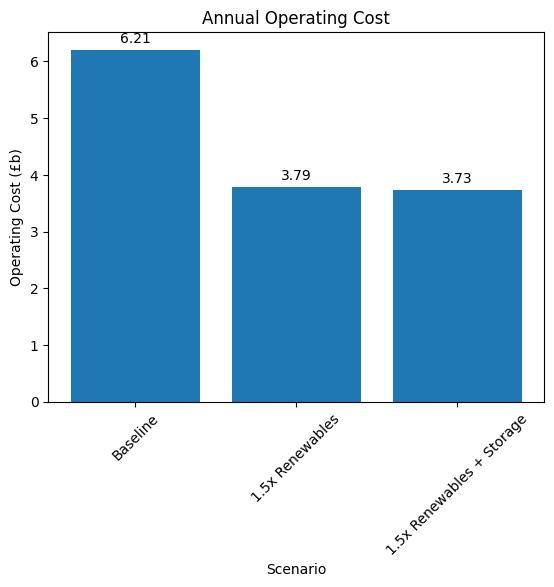

In [126]:

bars = plt.bar(["Baseline", "1.5x Renewables","1.5x Renewables + Storage"],
               [baseline_annual_operating_cost,scenario_b_operating_cost,scenario_c_operating_cost])

plt.bar_label(bars, fmt = "%.2f", padding = 3)

plt.xticks(rotation = 45)
plt.xlabel("Scenario")
plt.ylabel("Operating Cost (£b)")
plt.title("Annual Operating Cost")
plt

Text(0.5, 1.0, 'Gas Generation by Scenario')

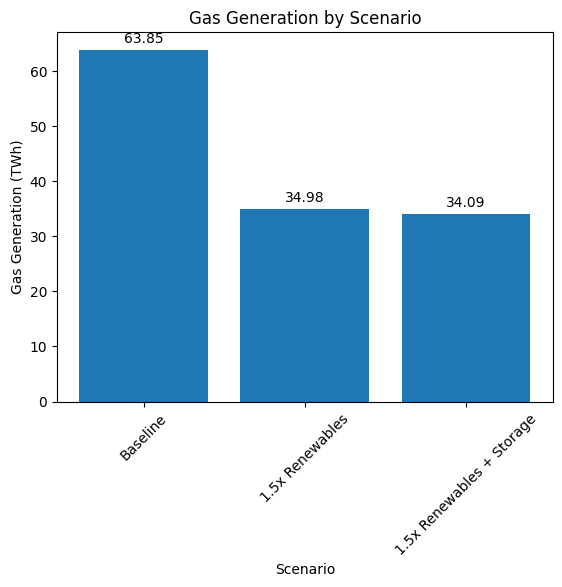

In [127]:

bars = plt.bar(["Baseline", "1.5x Renewables","1.5x Renewables + Storage"],
               [baseline_annual_gas,scenario_b_annual_gas,scenario_c_annual_gas])

plt.bar_label(bars, fmt = "%.2f", padding = 3)



plt.xticks(rotation = 45)
plt.xlabel("Scenario")
plt.ylabel("Gas Generation (TWh)")
plt.title("Gas Generation by Scenario")


Text(0.5, 1.0, 'Total Curtailment by Scenario')

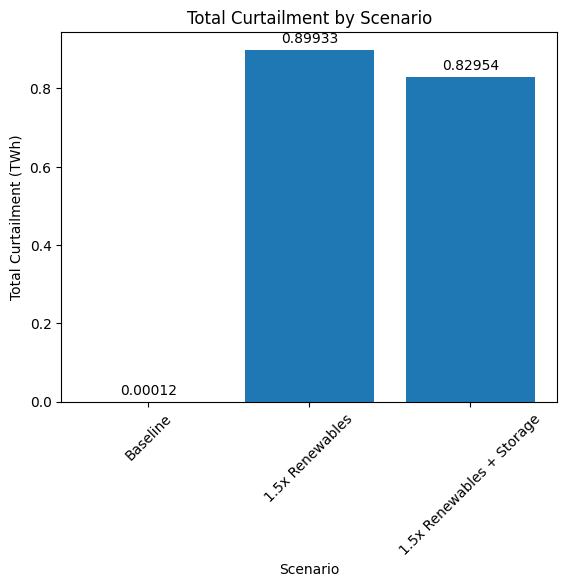

In [128]:

bars = plt.bar(["Baseline", "1.5x Renewables","1.5x Renewables + Storage"],
               [baseline_total_renewable_curtailment,scenario_b_total_renewable_curtailment,scenario_c_total_renewable_curtailmet])

plt.bar_label(bars, fmt = "%.5f", padding = 3)





plt.xticks(rotation = 45)
plt.xlabel("Scenario")
plt.ylabel("Total Curtailment (TWh)")
plt.title("Total Curtailment by Scenario")


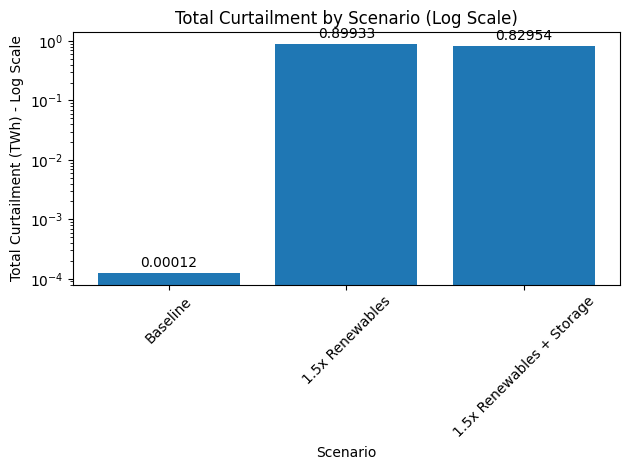

In [133]:

bars = plt.bar(["Baseline", "1.5x Renewables","1.5x Renewables + Storage"],
               [baseline_total_renewable_curtailment,scenario_b_total_renewable_curtailment,scenario_c_total_renewable_curtailmet])

plt.bar_label(bars, fmt = "%.5f", padding = 2)



plt.yscale('log')




plt.xticks(rotation=45)
plt.xlabel("Scenario")
plt.ylabel("Total Curtailment (TWh) - Log Scale")
plt.title("Total Curtailment by Scenario (Log Scale)")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Avg Marginal Price by Scenario')

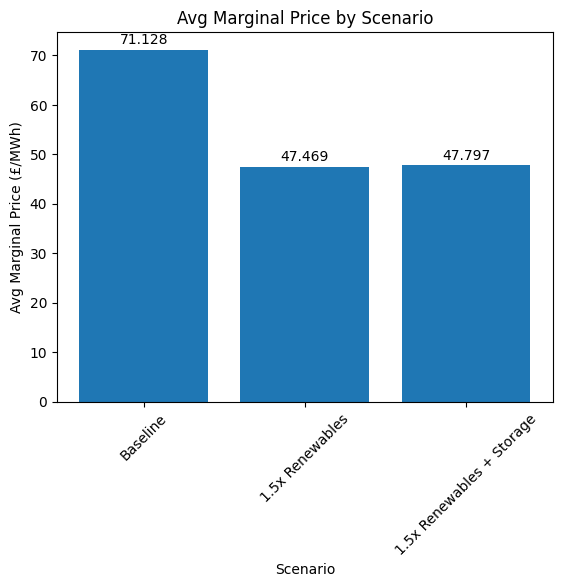

In [130]:


bars = plt.bar(["Baseline", "1.5x Renewables","1.5x Renewables + Storage"],
               [baseline_df["Marginal Price"].mean(),scenario_b_result_df["Scenario B Marginal Price"].mean(),scenario_c_result_df["Scenario C Marginal Price"].mean()])

plt.bar_label(bars, fmt = "%.3f", padding = 2)



plt.xticks(rotation = 45)
plt.xlabel("Scenario")
plt.ylabel("Avg Marginal Price (£/MWh)")
plt.title("Avg Marginal Price by Scenario")


# Scenario Analysis - A Summary

A higher reneawability scenario was developed by increasing the wind and solar availbility by 1.5x their baselines, whilst keeping demand and conventional generaion the same.

The scenearios investigated were:
- Scenario A: 2025 Baseline
- Scenario B: 1.5x Wind and Solar Availabilty
- Scenario C: 1.5x Wind and Solar Availability + Storage

Increasing the renewable availbility reduced the dependence on the higher cost generation significantly. Annual gas generation fell from approximately 64 TWh to around 35 TWh in scenario B and similarly, the modelled operating cost also fell from approximately £6.2 billion to around £3.8 billion.

The higher renewability scenario reduced the average marginal price proxy from around £71 to around £48. However, it should be noted that the amount of curatilment also increased from zero in the baseline model to around 0.90 TWh in scenario B.

In Scenario C, storage was added, this reduced the operating cost further from nearly £3.7 billion, gas generation was reduced to nearly 34 TWh and renewable curatailment to nearly 0.8 TWh. Scearnio C saw biomass generation completely eliminated in the optimised dispatch whilst the battery discharged approximately 1.1 TWh over 2025.

The average marginal price proxy did increase slightly from £47.47/MWh to £47.80/MWh when storage was introduced. This reflects the oppurtunity created by storage instead of a deteriation in system performance.

OVerall, the scenario analysis demonstrated that increased renewable availability can reduce fossil fuel dependence on generation by a sustantial amount in terms of actual eelctricity generaiton, operating costs and modelled marginal prices. However, it does result in increased curtailment. Battery storage does aid in recovering some of the curtailment and provides additional reductions in gas use and operating costs.

In [134]:
scenario_analysis_df.to_csv("/content/gridflow_2025_scenario_comparison.csv", index = False)